# Lab 1: Data Visualization, Data Preprocessing, and Statistical Analysis

**Name:** Sai Sravani Pillarisetty
**Course:** MSCS 634 – Advanced Big Data and Data Mining
**Lab:** Lab 1 – Data Visualization, Preprocessing, and Statistical Analysis

## Step 1: Data Collection

For this lab I used the **BigMart Sales** dataset, which is available on Kaggle. It contains sales data for
products sold in 10 different BigMart stores (outlets) in 2013. Each row is one product sold in one outlet.

I chose this dataset because it is sales data and it has some missing values and outliers, so it is a good
dataset for practicing preprocessing.

Main columns:
- `Item_Weight`, `Item_Visibility`, `Item_MRP` (price) – numeric product details
- `Item_Fat_Content`, `Item_Type` – product categories
- `Outlet_Size`, `Outlet_Location_Type`, `Outlet_Type`, `Outlet_Establishment_Year` – store details
- `Item_Outlet_Sales` – sales of the product in that store (the main variable I analyze)

In [1]:
# Importing the libraries used in this lab
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Loading the dataset into a Pandas DataFrame
df = pd.read_csv("data/bigmart_sales.csv")

# Printing the number of rows and columns
print("Shape of dataset:", df.shape)

Shape of dataset: (8523, 12)


In [3]:
# Displaying the first five rows
df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


The dataset has **8,523 rows and 12 columns**. Some values are already visible as missing (NaN) in the
`Outlet_Size` column.

## Step 2: Data Visualization

### 1. Histogram – Distribution of Sales

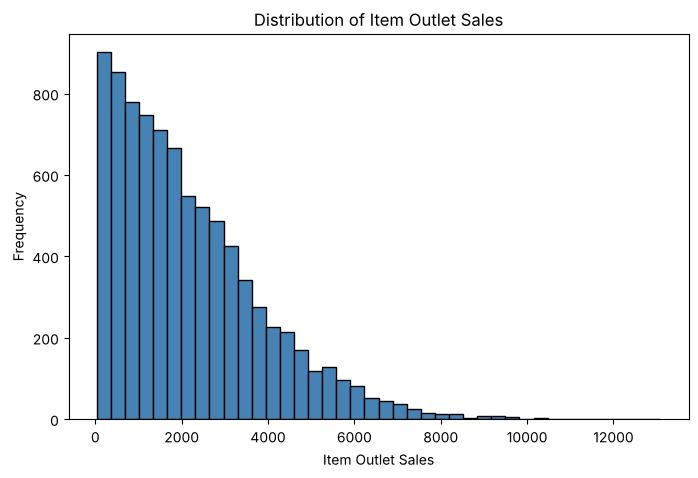

In [4]:
# Histogram of item sales
plt.figure(figsize=(8, 5))
plt.hist(df["Item_Outlet_Sales"], bins=40, color="steelblue", edgecolor="black")
plt.title("Distribution of Item Outlet Sales")
plt.xlabel("Item Outlet Sales")
plt.ylabel("Frequency")
plt.show()

**Insight:** The sales data is **right-skewed**. Most items have sales below 3,000, but a few items have
very high sales (up to about 13,000). These high values are possible outliers.

### 2. Scatter Plot – Item Price vs. Sales

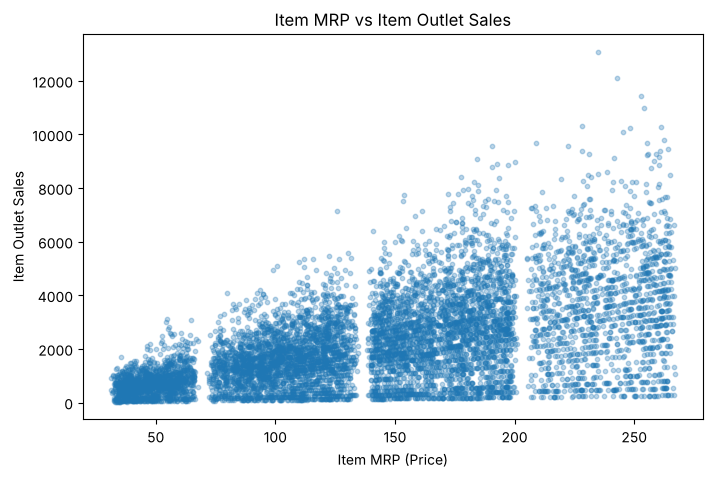

In [5]:
# Scatter plot of item price (MRP) against sales
plt.figure(figsize=(8, 5))
plt.scatter(df["Item_MRP"], df["Item_Outlet_Sales"], alpha=0.3, s=10)
plt.title("Item MRP vs Item Outlet Sales")
plt.xlabel("Item MRP (Price)")
plt.ylabel("Item Outlet Sales")
plt.show()

**Insight:** There is a **positive relationship** between price and sales: items with a higher MRP
generally have higher sales. The points also form four separate groups, which suggests the products
fall into four price ranges.

### 3. Line Plot – Average Sales by Outlet Establishment Year

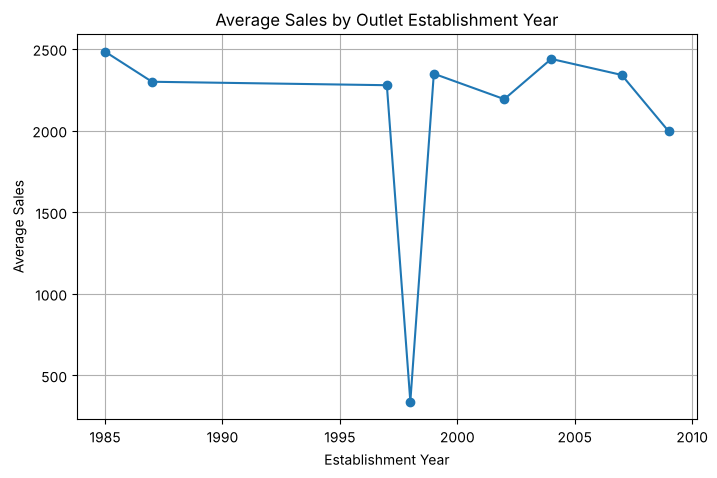

Outlet_Establishment_Year
1985    2483.68
1987    2299.00
1997    2277.84
1998     339.35
1999    2348.35
2002    2192.38
2004    2438.84
2007    2340.68
2009    1995.50
Name: Item_Outlet_Sales, dtype: float64


In [6]:
# Average sales for outlets grouped by the year they were opened
sales_by_year = df.groupby("Outlet_Establishment_Year")["Item_Outlet_Sales"].mean()

plt.figure(figsize=(8, 5))
plt.plot(sales_by_year.index, sales_by_year.values, marker="o")
plt.title("Average Sales by Outlet Establishment Year")
plt.xlabel("Establishment Year")
plt.ylabel("Average Sales")
plt.grid(True)
plt.show()

print(sales_by_year.round(2))

**Insight:** Average sales stay between about 2,000 and 2,500 for most years, so there is no clear
trend over time. The big drop in **1998** is an anomaly. The only outlet opened that year is a
Grocery Store, which has much lower sales than supermarkets.

### 4. Bar Chart – Average Sales by Outlet Type

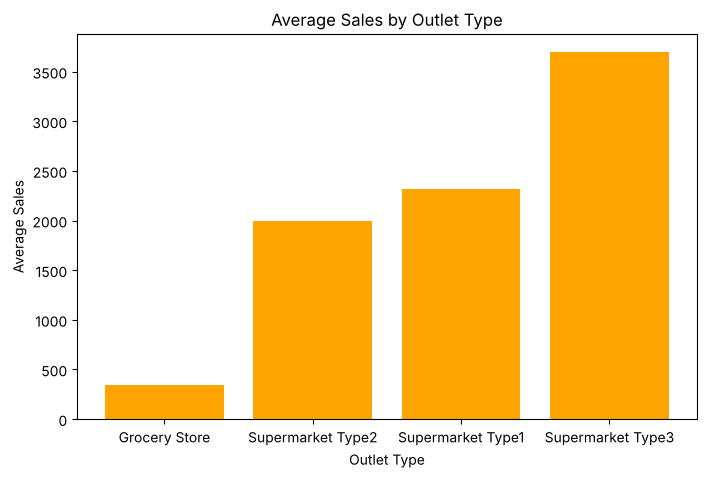

Outlet_Type
Grocery Store         339.83
Supermarket Type2    1995.50
Supermarket Type1    2316.18
Supermarket Type3    3694.04
Name: Item_Outlet_Sales, dtype: float64


In [7]:
# Average sales for each outlet type
sales_by_type = df.groupby("Outlet_Type")["Item_Outlet_Sales"].mean().sort_values()

plt.figure(figsize=(8, 5))
plt.bar(sales_by_type.index, sales_by_type.values, color="orange")
plt.title("Average Sales by Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Average Sales")
plt.show()

print(sales_by_type.round(2))

**Insight:** **Supermarket Type 3** has the highest average sales (about 3,694) and **Grocery Stores**
have the lowest (about 340). Outlet type has a big effect on sales.

### 5. Box Plot – Sales by Outlet Type

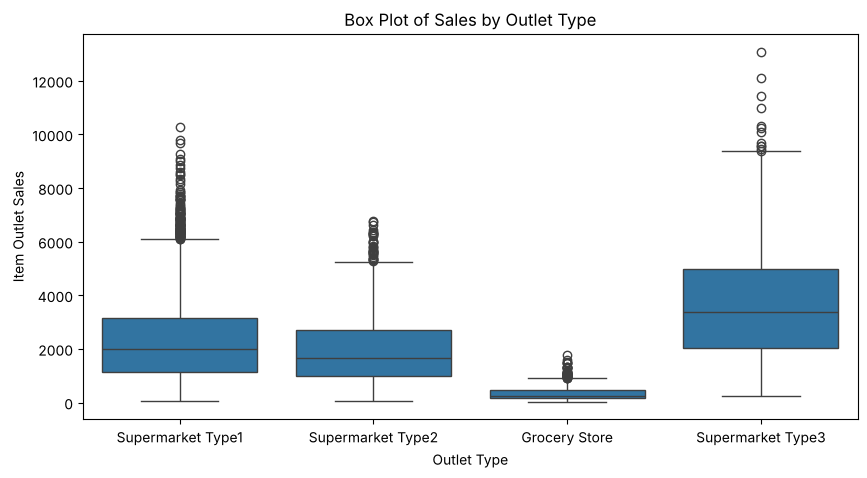

In [8]:
# Box plot to see the spread and outliers of sales for each outlet type
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Outlet_Type", y="Item_Outlet_Sales")
plt.title("Box Plot of Sales by Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Item Outlet Sales")
plt.show()

**Insight:** All outlet types have **outliers on the high side** (the dots above the boxes).
Supermarket Type 3 has the highest median and the largest spread, while Grocery Store sales are low
and close together.

### 6. Pie Chart – Share of Total Sales by Location Type

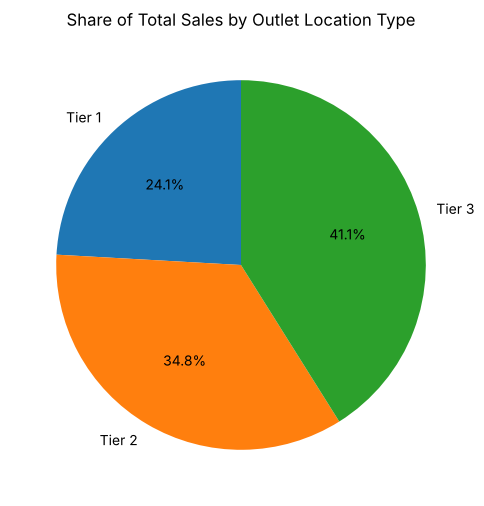

In [9]:
# Total sales for each location tier, shown as percentages
sales_by_tier = df.groupby("Outlet_Location_Type")["Item_Outlet_Sales"].sum()

plt.figure(figsize=(6, 6))
plt.pie(sales_by_tier, labels=sales_by_tier.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of Total Sales by Outlet Location Type")
plt.show()

**Insight:** **Tier 3** locations make the largest share of total sales (41.1%), followed by Tier 2
(34.8%) and Tier 1 (24.1%).

## Step 3: Data Preprocessing

### 1. Handling Missing Values

First, I checked for duplicate rows and fixed inconsistent labels in `Item_Fat_Content`.

In [10]:
# Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

# Item_Fat_Content uses different names for the same category
print("\nBefore fixing labels:")
print(df["Item_Fat_Content"].value_counts())

df["Item_Fat_Content"] = df["Item_Fat_Content"].replace(
    {"LF": "Low Fat", "low fat": "Low Fat", "reg": "Regular"})

print("\nAfter fixing labels:")
print(df["Item_Fat_Content"].value_counts())

Number of duplicate rows: 0

Before fixing labels:
Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

After fixing labels:
Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64


There are no duplicate rows. The labels "LF" and "low fat" were changed to "Low Fat", and "reg" was
changed to "Regular", so there are now only two categories.

**Detecting missing values:**

In [11]:
# Count missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

# Percentage of missing values
print("\nPercentage missing:")
print((df.isnull().sum() / len(df) * 100).round(2))

Missing values in each column:
Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

Percentage missing:
Item_Identifier               0.00
Item_Weight                  17.17
Item_Fat_Content              0.00
Item_Visibility               0.00
Item_Type                     0.00
Item_MRP                      0.00
Outlet_Identifier             0.00
Outlet_Establishment_Year     0.00
Outlet_Size                  28.28
Outlet_Location_Type          0.00
Outlet_Type                   0.00
Item_Outlet_Sales             0.00
dtype: float64


`Item_Weight` has **1,463** missing values (17.17%) and `Outlet_Size` has **2,410** missing values
(28.28%).

**Trying different techniques:** Before choosing a method, I compared the techniques on a few rows
that have a missing `Item_Weight`.

In [12]:
# Take a small sample of rows that includes missing weights
sample = df["Item_Weight"].iloc[5:12]

comparison = pd.DataFrame({
    "Original": sample,
    "Fill with 0": sample.fillna(0),                          # constant
    "Forward Fill": sample.ffill(),                            # previous value
    "Backward Fill": sample.bfill(),                           # next value
    "Mean": sample.fillna(df["Item_Weight"].mean()),           # column mean
    "Mode": sample.fillna(df["Item_Weight"].mode()[0]),        # most common value
})
comparison

,Original,Fill with 0,Forward Fill,Backward Fill,Mean,Mode
5,10.395,10.395,10.395,10.395,10.395000,10.395
6,13.650,13.650,13.650,13.650,13.650000,13.650
7,NaN,0.000,13.650,16.200,12.857645,12.150
8,16.200,16.200,16.200,16.200,16.200000,16.200
9,19.200,19.200,19.200,19.200,19.200000,19.200
10,11.800,11.800,11.800,11.800,11.800000,11.800
11,18.500,18.500,18.500,18.500,18.500000,18.500


In [13]:
# Dropping rows or columns (not saved, only to see the effect)
print("Rows if we drop all rows with missing values:", df.dropna().shape[0])

# Drop columns that have more than 25% missing values
print("Columns left after dropping columns with >25% missing:",
      list(df.dropna(axis=1, thresh=int(0.75 * len(df))).columns))

Rows if we drop all rows with missing values: 4650
Columns left after dropping columns with >25% missing: ['Item_Identifier', 'Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type', 'Item_MRP', 'Outlet_Identifier', 'Outlet_Establishment_Year', 'Outlet_Location_Type', 'Outlet_Type', 'Item_Outlet_Sales']


Dropping rows would remove almost half of the data (8,523 → 4,650 rows), and dropping the
`Outlet_Size` column would lose useful information. A constant of 0 does not make sense for weight.
So I decided to:
- Fill `Item_Weight` with the **mean** (it is a numeric column)
- Fill `Outlet_Size` with the **mode** (it is a categorical column)

**Before handling missing values:**

In [14]:
# Show some rows that have missing values
rows_with_missing = df[df["Item_Weight"].isnull() | df["Outlet_Size"].isnull()].head(8)
rows_with_missing

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
3,FDX07,19.2,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
7,FDP10,NaN,Low Fat,0.127470,Snack Foods,107.7622,OUT027,1985,Medium,Tier 3,Supermarket Type3,4022.7636
8,FDH17,16.2,Regular,0.016687,Frozen Foods,96.9726,OUT045,2002,NaN,Tier 2,Supermarket Type1,1076.5986
9,FDU28,19.2,Regular,0.094450,Frozen Foods,187.8214,OUT017,2007,NaN,Tier 2,Supermarket Type1,4710.5350
18,DRI11,NaN,Low Fat,0.034238,Hard Drinks,113.2834,OUT027,1985,Medium,Tier 3,Supermarket Type3,2303.6680
21,FDW12,NaN,Regular,0.035400,Baking Goods,144.5444,OUT027,1985,Medium,Tier 3,Supermarket Type3,4064.0432
23,FDC37,NaN,Low Fat,0.057557,Baking Goods,107.6938,OUT019,1985,Small,Tier 1,Grocery Store,214.3876
25,NCD06,13.0,Low Fat,0.099887,Household,45.9060,OUT017,2007,NaN,Tier 2,Supermarket Type1,838.9080


In [15]:
# Fill Item_Weight with the mean
df["Item_Weight"] = df["Item_Weight"].fillna(df["Item_Weight"].mean())

# Fill Outlet_Size with the mode
df["Outlet_Size"] = df["Outlet_Size"].fillna(df["Outlet_Size"].mode()[0])

print("Mean used for Item_Weight:", round(df["Item_Weight"].mean(), 2))
print("Mode used for Outlet_Size:", df["Outlet_Size"].mode()[0])

Mean used for Item_Weight: 12.86
Mode used for Outlet_Size: Medium


**After handling missing values:**

In [16]:
# The same rows after filling
print("Missing values after handling:")
print(df.isnull().sum())

df.loc[rows_with_missing.index]

Missing values after handling:
Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
dtype: int64


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
3,FDX07,19.200000,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,Medium,Tier 3,Grocery Store,732.3800
7,FDP10,12.857645,Low Fat,0.127470,Snack Foods,107.7622,OUT027,1985,Medium,Tier 3,Supermarket Type3,4022.7636
8,FDH17,16.200000,Regular,0.016687,Frozen Foods,96.9726,OUT045,2002,Medium,Tier 2,Supermarket Type1,1076.5986
9,FDU28,19.200000,Regular,0.094450,Frozen Foods,187.8214,OUT017,2007,Medium,Tier 2,Supermarket Type1,4710.5350
18,DRI11,12.857645,Low Fat,0.034238,Hard Drinks,113.2834,OUT027,1985,Medium,Tier 3,Supermarket Type3,2303.6680
21,FDW12,12.857645,Regular,0.035400,Baking Goods,144.5444,OUT027,1985,Medium,Tier 3,Supermarket Type3,4064.0432
23,FDC37,12.857645,Low Fat,0.057557,Baking Goods,107.6938,OUT019,1985,Small,Tier 1,Grocery Store,214.3876
25,NCD06,13.000000,Low Fat,0.099887,Household,45.9060,OUT017,2007,Medium,Tier 2,Supermarket Type1,838.9080


All missing values are now filled and no rows were removed.

### 2. Outlier Detection and Removal

I used the **IQR method** on `Item_Outlet_Sales`. Any value below Q1 − 1.5×IQR or above
Q3 + 1.5×IQR is an outlier.

In [17]:
# IQR calculation
Q1 = df["Item_Outlet_Sales"].quantile(0.25)
Q3 = df["Item_Outlet_Sales"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))

Q1: 834.25
Q3: 3101.3
IQR: 2267.05
Lower bound: -2566.33
Upper bound: 6501.87


In [18]:
# Finding the outliers
outliers = df[(df["Item_Outlet_Sales"] < lower_bound) | (df["Item_Outlet_Sales"] > upper_bound)]

print("Number of outliers:", len(outliers))
outliers[["Item_Type", "Item_MRP", "Outlet_Type", "Item_Outlet_Sales"]].head(10)

Number of outliers: 186


,Item_Type,Item_MRP,Outlet_Type,Item_Outlet_Sales
43,Canned,259.9278,Supermarket Type2,6768.5228
130,Canned,180.5976,Supermarket Type3,7968.2944
132,Health and Hygiene,224.4404,Supermarket Type3,6976.2524
145,Frozen Foods,246.3802,Supermarket Type1,7370.4060
203,Baking Goods,177.9370,Supermarket Type3,6704.6060
240,Household,251.3724,Supermarket Type1,6795.1548
243,Fruits and Vegetables,227.6062,Supermarket Type1,7222.5984
275,Meat,173.1738,Supermarket Type3,7298.4996
276,Fruits and Vegetables,256.4988,Supermarket Type1,7452.9652
304,Soft Drinks,224.9720,Supermarket Type1,7696.6480


Rows before removing outliers: 8523
Rows after removing outliers: 8337


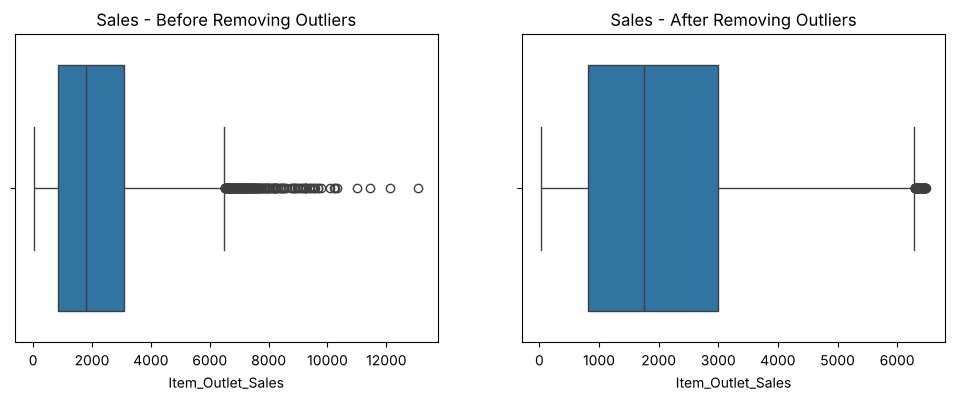

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,Medium,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [19]:
# Removing the outliers
df_no_outliers = df[(df["Item_Outlet_Sales"] >= lower_bound) &
                    (df["Item_Outlet_Sales"] <= upper_bound)]

print("Rows before removing outliers:", df.shape[0])
print("Rows after removing outliers:", df_no_outliers.shape[0])

# Box plots before and after
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["Item_Outlet_Sales"], ax=axes[0])
axes[0].set_title("Sales - Before Removing Outliers")
sns.boxplot(x=df_no_outliers["Item_Outlet_Sales"], ax=axes[1])
axes[1].set_title("Sales - After Removing Outliers")
plt.show()

df_no_outliers.head()

The IQR method found **186 outliers**, all on the high side (sales above 6,501.87). After removing them,
the dataset has **8,337 rows** and the maximum sales value is much lower. A few points still appear
outside the whiskers in the "after" box plot because the quartiles are recalculated on the new data.

### 3. Data Reduction

**Sampling:**

In [20]:
print("Original size:", df_no_outliers.shape)

# Sampling by number - select 1000 random rows
sample_number = df_no_outliers.sample(n=1000, random_state=42)
print("Sample by number (n=1000):", sample_number.shape)

# Sampling by percentage - select 20% of the rows
sample_percent = df_no_outliers.sample(frac=0.2, random_state=42)
print("Sample by percentage (20%):", sample_percent.shape)

sample_number.head()

Original size: (8337, 12)
Sample by number (n=1000): (1000, 12)
Sample by percentage (20%): (1667, 12)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
3552,FDD40,12.857645,Regular,0.014722,Dairy,193.6162,OUT027,1985,Medium,Tier 3,Supermarket Type3,5195.2374
2360,FDH14,17.100000,Regular,0.046809,Canned,141.4838,OUT046,1997,Small,Tier 1,Supermarket Type1,1404.8380
8159,FDC15,18.100000,Low Fat,0.178694,Dairy,158.9288,OUT018,2009,Medium,Tier 3,Supermarket Type2,1571.2880
958,FDO13,7.865000,Low Fat,0.061405,Breakfast,166.3526,OUT017,2007,Medium,Tier 2,Supermarket Type1,1973.4312
5483,FDM13,6.425000,Low Fat,0.063433,Breakfast,132.8626,OUT018,2009,Medium,Tier 3,Supermarket Type2,524.6504


**Dimension elimination:** `Item_Identifier` and `Outlet_Identifier` are only ID codes, so they are not
useful for analysis. I dropped these two columns.

In [21]:
print("Before dropping columns:", df_no_outliers.shape)
print(list(df_no_outliers.columns))

df_reduced = df_no_outliers.drop(columns=["Item_Identifier", "Outlet_Identifier"])

print("\nAfter dropping columns:", df_reduced.shape)
print(list(df_reduced.columns))

df_reduced.head()

Before dropping columns: (8337, 12)
['Item_Identifier', 'Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type', 'Item_MRP', 'Outlet_Identifier', 'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type', 'Item_Outlet_Sales']

After dropping columns: (8337, 10)
['Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type', 'Item_MRP', 'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type', 'Item_Outlet_Sales']


,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,9.30,Low Fat,0.016047,Dairy,249.8092,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,5.92,Regular,0.019278,Soft Drinks,48.2692,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,17.50,Low Fat,0.016760,Meat,141.6180,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,1998,Medium,Tier 3,Grocery Store,732.3800
4,8.93,Low Fat,0.000000,Household,53.8614,1987,High,Tier 3,Supermarket Type1,994.7052


The number of rows went from 8,337 to 1,000 (sampling by number) and 1,667 (sampling by percentage),
and the number of columns went from 12 to 10.

### 4. Data Scaling and Discretization

In [22]:
df_scaled = df_reduced.copy()

# Before scaling
print("Before scaling:")
print(df_scaled[["Item_MRP", "Item_Weight", "Item_Outlet_Sales"]].describe().round(2))

# Min-Max Scaling on Item_MRP (values between 0 and 1)
df_scaled["MRP_MinMax"] = (df_scaled["Item_MRP"] - df_scaled["Item_MRP"].min()) / \
                          (df_scaled["Item_MRP"].max() - df_scaled["Item_MRP"].min())

# Z-score Standardization on Item_Weight (mean 0, standard deviation 1)
df_scaled["Weight_Zscore"] = (df_scaled["Item_Weight"] - df_scaled["Item_Weight"].mean()) / \
                             df_scaled["Item_Weight"].std()

# Decimal Scaling on Item_Outlet_Sales (divide by 10^j)
j = len(str(int(df_scaled["Item_Outlet_Sales"].max())))
df_scaled["Sales_Decimal"] = df_scaled["Item_Outlet_Sales"] / (10 ** j)

print("\nAfter scaling:")
print(df_scaled[["MRP_MinMax", "Weight_Zscore", "Sales_Decimal"]].describe().round(2))

df_scaled[["Item_MRP", "MRP_MinMax", "Item_Weight", "Weight_Zscore",
           "Item_Outlet_Sales", "Sales_Decimal"]].head()

Before scaling:
       Item_MRP  Item_Weight  Item_Outlet_Sales
count   8337.00      8337.00            8337.00
mean     139.16        12.86            2059.36
std       61.55         4.25            1506.10
min       31.29         4.56              33.29
25%       93.05         9.30             810.94
50%      141.22        12.86            1747.06
75%      183.70        16.10            2998.10
max      266.89        21.35            6478.23

After scaling:
       MRP_MinMax  Weight_Zscore  Sales_Decimal
count     8337.00        8337.00        8337.00
mean         0.46           0.00           0.21
std          0.26           1.00           0.15
min          0.00          -1.95           0.00
25%          0.26          -0.84           0.08
50%          0.47           0.00           0.17
75%          0.65           0.76           0.30
max          1.00           2.00           0.65


,Item_MRP,MRP_MinMax,Item_Weight,Weight_Zscore,Item_Outlet_Sales,Sales_Decimal
0,249.8092,0.927507,9.30,-0.836775,3735.1380,0.373514
1,48.2692,0.072068,5.92,-1.631993,443.4228,0.044342
2,141.6180,0.468288,17.50,1.092450,2097.2700,0.209727
3,182.0950,0.640093,19.20,1.492412,732.3800,0.073238
4,53.8614,0.095805,8.93,-0.923826,994.7052,0.099471


After scaling, `MRP_MinMax` is between 0 and 1, `Weight_Zscore` has a mean of 0 and a standard
deviation of 1, and `Sales_Decimal` values are all less than 1.

**Discretization:** I converted `Item_MRP` (a continuous value) into four price categories.

In [23]:
# Discretize Item_MRP into 4 price categories
df_scaled["Price_Category"] = pd.cut(df_scaled["Item_MRP"], bins=4,
                                     labels=["Low", "Medium", "High", "Very High"])

# Before and after
print(df_scaled[["Item_MRP", "Price_Category"]].head(10))

print("\nNumber of items in each price category:")
print(df_scaled["Price_Category"].value_counts())

   Item_MRP Price_Category
0  249.8092      Very High
1   48.2692            Low
2  141.6180         Medium
3  182.0950           High
4   53.8614            Low
5   51.4008            Low
6   57.6588            Low
7  107.7622         Medium
8   96.9726         Medium
9  187.8214           High

Number of items in each price category:
Price_Category
Medium       2627
High         2466
Low          1973
Very High    1271
Name: count, dtype: int64


In [24]:
# Save the cleaned dataset
df.to_csv("data/bigmart_sales_cleaned.csv", index=False)
df_scaled.to_csv("data/bigmart_sales_preprocessed.csv", index=False)
print("Files saved.")

Files saved.


## Step 4: Statistical Analysis

I used the cleaned dataset (missing values filled) for this section.

### 1. General Overview of Data

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   str    
 1   Item_Weight                8523 non-null   float64
 2   Item_Fat_Content           8523 non-null   str    
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   str    
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   str    
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                8523 non-null   str    
 9   Outlet_Location_Type       8523 non-null   str    
 10  Outlet_Type                8523 non-null   str    
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


In [26]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,8523.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.226124,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,9.310000,0.026989,93.826500,1987.000000,834.247400
50%,12.857645,0.053931,143.012800,1999.000000,1794.331000
75%,16.000000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


The dataset has 8,523 rows and 12 columns, with 5 numeric columns and 7 text (object) columns. There
are no missing values after cleaning.

### 2. Central Tendency Measures

In [27]:
numeric_cols = ["Item_Weight", "Item_Visibility", "Item_MRP", "Item_Outlet_Sales"]

central_tendency = pd.DataFrame({
    "Minimum": df[numeric_cols].min(),
    "Maximum": df[numeric_cols].max(),
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Mode": df[numeric_cols].mode().iloc[0],
})
central_tendency.round(3)

,Minimum,Maximum,Mean,Median,Mode
Item_Weight,4.555,21.350,12.858,12.858,12.858
Item_Visibility,0.000,0.328,0.066,0.054,0.000
Item_MRP,31.290,266.888,140.993,143.013,172.042
Item_Outlet_Sales,33.290,13086.965,2181.289,1794.331,958.752


- For `Item_Outlet_Sales`, the **mean (2,181.29) is higher than the median (1,794.33)**. This shows the
  data is right-skewed because of the high-selling items.
- For `Item_MRP`, the mean (140.99) and median (143.01) are close, so prices are fairly balanced.
- The mode of `Item_Weight` is the mean value (12.86), because that value was used to fill the 1,463
  missing weights.
- The mode of `Item_Visibility` is 0, but a product that is sold should have some shelf space, so these
  zeros may be data entry errors.

### 3. Dispersion Measures

In [28]:
dispersion = pd.DataFrame({
    "Range": df[numeric_cols].max() - df[numeric_cols].min(),
    "Q1": df[numeric_cols].quantile(0.25),
    "Q2 (Median)": df[numeric_cols].quantile(0.50),
    "Q3": df[numeric_cols].quantile(0.75),
    "IQR": df[numeric_cols].quantile(0.75) - df[numeric_cols].quantile(0.25),
    "Variance": df[numeric_cols].var(),
    "Std Deviation": df[numeric_cols].std(),
})
dispersion.round(3)

,Range,Q1,Q2 (Median),Q3,IQR,Variance,Std Deviation
Item_Weight,16.795,9.310,12.858,16.000,6.690,17.860,4.226
Item_Visibility,0.328,0.027,0.054,0.095,0.068,0.003,0.052
Item_MRP,235.598,93.826,143.013,185.644,91.817,3878.184,62.275
Item_Outlet_Sales,13053.675,834.247,1794.331,3101.296,2267.049,2912140.938,1706.500


`Item_Outlet_Sales` has the largest spread, with a range of 13,053.67 and a standard deviation of
1,706.50. The middle 50% of sales are between 834.25 and 3,101.30 (IQR = 2,267.05). `Item_MRP` has a
standard deviation of 62.28.

### 4. Correlation Analysis

                           Item_Weight  Item_Visibility  Item_MRP  \
Item_Weight                      1.000           -0.012     0.025   
Item_Visibility                 -0.012            1.000    -0.001   
Item_MRP                         0.025           -0.001     1.000   
Outlet_Establishment_Year       -0.008           -0.075     0.005   
Item_Outlet_Sales                0.012           -0.129     0.568   

                           Outlet_Establishment_Year  Item_Outlet_Sales  
Item_Weight                                   -0.008              0.012  
Item_Visibility                               -0.075             -0.129  
Item_MRP                                       0.005              0.568  
Outlet_Establishment_Year                      1.000             -0.049  
Item_Outlet_Sales                             -0.049              1.000  


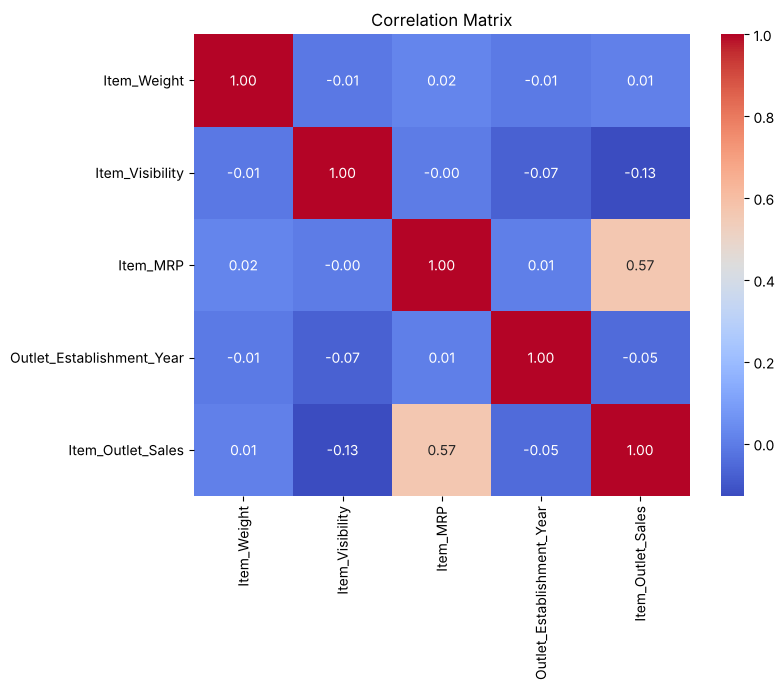

In [29]:
# Correlation matrix of the numeric columns
corr_cols = ["Item_Weight", "Item_Visibility", "Item_MRP",
             "Outlet_Establishment_Year", "Item_Outlet_Sales"]
correlation = df[corr_cols].corr()
print(correlation.round(3))

# Heatmap of the correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

- `Item_MRP` and `Item_Outlet_Sales` have a **moderate positive correlation (0.57)**, which matches the
  scatter plot: higher price leads to higher sales.
- `Item_Visibility` has a **weak negative correlation** with sales (−0.13).
- `Item_Weight` and `Outlet_Establishment_Year` have almost no correlation with sales.

## Conclusion

- Price (MRP) is the numeric variable most related to sales.
- Outlet type has a big impact: Supermarket Type 3 sells the most and Grocery Stores sell the least.
- Sales are right-skewed with 186 high outliers.
- The missing values were filled with the mean and mode, and the data was reduced, scaled and
  discretized to prepare it for further analysis.